# 03 Evaluate: how good are the forecasts in the backtest?

**Purpose:** Compute the backtest errors of all candidate models, per horizon, in units a planner understands; compare the models at the main horizon ($h = 2$), also without the crisis periods and year by year.
**Input:** `../data/processed/backtest_forecasts.csv` (from `02_estimate.ipynb`).
**Output:** `../output/tables/03_backtest_errors.csv`, `../output/tables/03_backtest_errors_by_year_h2.csv` and two figures in `../output/figures/`.

This notebook uses **only the backtest** (2013 to September 2024). The test period stays untouched until we have chosen our final model (notebook 209, Step 7: choose before you test).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)
plt.style.use("seaborn-v0_8-muted")

## 1. Load the forecasts and compute the errors

For every forecast we compute two errors:

- the **absolute error in persons**, $|y - \hat y|$: the mean of it (MAE) says by how many applications per month we miss on average. This is the number a planner at SEM understands (notebook 108b, deck 08; notebook 209, Step 8).
- the **squared error in logs**, $(\log y - \widehat{\log y})^2$: the root of its mean (RMSE in logs) is the error measure of our project plan. An error of 0.10 in logs is roughly 10% off (notebook 209).

In [2]:
forecasts = pd.read_csv("../data/processed/backtest_forecasts.csv")
forecasts["month"] = pd.to_datetime(forecasts["month"])
forecasts["origin"] = pd.to_datetime(forecasts["origin"])

forecasts["abs_error"] = (forecasts["actual"] - forecasts["forecast"]).abs()
forecasts["sq_error_log"] = (forecasts["actual_log"] - forecasts["forecast_log"]) ** 2

print("Forecasts:", forecasts.shape[0], "| models:", forecasts["model"].nunique(),
      "| forecast months from", forecasts["month"].min(), "to", forecasts["month"].max())

Forecasts: 2100 | models: 5 | forecast months from 2013-01-01 00:00:00 to 2024-09-01 00:00:00


## 2. Errors of all models for all horizons

We put the two simple rules first, then the three (S)ARIMA models.

In [3]:
model_order = ["Seasonal naive", "12-month average", "ARIMA(1,1,0)",
               "SARIMA(1,1,0)(1,0,0)12", "SARIMA(0,1,1)(0,1,1)12"]
baselines = ["Seasonal naive", "12-month average"]

def error_table(data):
    # MAE in persons and RMSE in logs for every model and horizon
    grouped = data.groupby(["model", "h"])
    table = pd.DataFrame({
        "MAE (persons)": grouped["abs_error"].mean(),
        "RMSE (log)": np.sqrt(grouped["sq_error_log"].mean()),
        "forecasts": grouped["abs_error"].size(),
    }).reset_index()
    return table

errors = error_table(forecasts)

mae = errors.pivot(index="model", columns="h", values="MAE (persons)").loc[model_order].round(0)
mae.columns = [f"MAE h={h}" for h in mae.columns]
rmse = errors.pivot(index="model", columns="h", values="RMSE (log)").loc[model_order].round(3)
rmse.columns = [f"RMSE log h={h}" for h in rmse.columns]

overview = pd.concat([mae, rmse], axis=1)
overview.to_csv("../output/tables/03_backtest_errors.csv")
overview

,MAE h=1,MAE h=2,MAE h=3,RMSE log h=1,RMSE log h=2,RMSE log h=3
model,,,,,,
Seasonal naive,679.0,681.0,682.0,0.436,0.437,0.438
12-month average,487.0,528.0,558.0,0.317,0.342,0.362
"ARIMA(1,1,0)",272.0,388.0,499.0,0.207,0.292,0.361
"SARIMA(1,1,0)(1,0,0)12",260.0,371.0,468.0,0.199,0.282,0.347
"SARIMA(0,1,1)(0,1,1)12",254.0,369.0,458.0,0.191,0.274,0.328


**What we see.**
- At every horizon, the order is the same: the seasonal naive has the largest errors (about 680 persons), then the 12-month average, then the three (S)ARIMA models.
- SARIMA(0,1,1)(0,1,1)12 has the lowest MAE and RMSE (log) at all three horizons, but the three (S)ARIMA models are close to each other (at $h=2$: 369, 371 and 388).
- The errors of the (S)ARIMA models grow with the horizon (for SARIMA(0,1,1)(0,1,1)12: 254, 369, 458 persons). The seasonal naive has almost the same error at every horizon, because its forecast for a month is always the value 12 months earlier, whatever the origin.

## 3. The main comparison: $h = 2$

Our project plan fixes one main comparison (Johannes' feedback): the **best simple baseline** against the **best (S)ARIMA model**, at the main horizon $h = 2$. We read both from the table above with code, so that nothing is chosen by hand.

In [4]:
h2 = errors[errors["h"] == 2].set_index("model")

best_baseline = h2.loc[baselines, "MAE (persons)"].idxmin()
sarima_models = [m for m in model_order if m not in baselines]
best_sarima = h2.loc[sarima_models, "MAE (persons)"].idxmin()

mae_base = h2.loc[best_baseline, "MAE (persons)"]
mae_best = h2.loc[best_sarima, "MAE (persons)"]
rmse_base = h2.loc[best_baseline, "RMSE (log)"]
rmse_best = h2.loc[best_sarima, "RMSE (log)"]

print(f"Best simple baseline at h=2:  {best_baseline:25s} MAE {mae_base:5.0f} persons   RMSE (log) {rmse_base:.3f}")
print(f"Best (S)ARIMA model at h=2:   {best_sarima:25s} MAE {mae_best:5.0f} persons   RMSE (log) {rmse_best:.3f}")
print(f"Improvement of the (S)ARIMA model: {100 * (1 - mae_best / mae_base):.0f}% lower MAE, "
      f"{100 * (1 - rmse_best / rmse_base):.0f}% lower RMSE (log)")
average_actual = forecasts[forecasts["h"] == 2]["actual"].mean()
print(f"For comparison, average actual number of applications in these months: {average_actual:.0f}")

Best simple baseline at h=2:  12-month average          MAE   528 persons   RMSE (log) 0.342
Best (S)ARIMA model at h=2:   SARIMA(0,1,1)(0,1,1)12    MAE   369 persons   RMSE (log) 0.274
Improvement of the (S)ARIMA model: 30% lower MAE, 20% lower RMSE (log)
For comparison, average actual number of applications in these months: 1850


**What we see.** At the main horizon $h = 2$, the best simple baseline is the 12-month average (MAE 528 persons, RMSE 0.342 in logs), and the best (S)ARIMA model is SARIMA(0,1,1)(0,1,1)12 (MAE 369 persons, RMSE 0.274). The (S)ARIMA model misses by about 160 fewer applications per month: 30% lower MAE and 20% lower RMSE (log). For comparison, there were on average 1,850 applications per month in these months.

**What this means for us.** Using the series' own past in a SARIMA model clearly helps compared with the simple rules. From now on, the best (S)ARIMA model is the **benchmark** that the models of the next steps (Ridge/Lasso with lags, indicators) must beat, as in our project plan.

## 4. Without the crisis periods

The backtest contains two exceptional periods: the 2015-16 crisis and the drop of 2020. As planned, we report the errors also without the forecast months of these years (2015-01 to 2016-12 and 2020-01 to 2020-12), and for the recent years only (from 2022). These are **evaluation periods**: the models themselves did not know about them.

In [5]:
month = forecasts["month"]
crisis = ((month >= "2015-01-01") & (month <= "2016-12-01")) | ((month >= "2020-01-01") & (month <= "2020-12-01"))

periods = {
    "all backtest months": forecasts,
    "without 2015-16 and 2020": forecasts[~crisis],
    "from 2022": forecasts[month >= "2022-01-01"],
}

rows = []
for period_name, data in periods.items():
    table = error_table(data[data["h"] == 2])
    table["period"] = period_name
    rows.append(table)
by_period = pd.concat(rows)

by_period.pivot(index="model", columns="period", values="MAE (persons)").loc[model_order, list(periods)].round(0)

period,all backtest months,without 2015-16 and 2020,from 2022
model,,,
Seasonal naive,681.0,523.0,681.0
12-month average,528.0,369.0,512.0
"ARIMA(1,1,0)",388.0,304.0,496.0
"SARIMA(1,1,0)(1,0,0)12",371.0,281.0,450.0
"SARIMA(0,1,1)(0,1,1)12",369.0,295.0,427.0


In [6]:
# Number of forecast months in each period (h = 2)
by_period[by_period["model"] == "Seasonal naive"].set_index("period")["forecasts"]

period
all backtest months         140
without 2015-16 and 2020    104
from 2022                    33
Name: forecasts, dtype: int64

**What we see.** (The three periods contain 140, 104 and 33 forecast months.)
- Without 2015-16 and 2020, all errors are smaller: the 12-month average goes from 528 to 369 persons, the best (S)ARIMA model from 369 to 281. The (S)ARIMA models are still clearly better, but the gap shrinks (from 159 to 88 persons), and the best (S)ARIMA model is now SARIMA(1,1,0)(1,0,0)12 (281) instead of SARIMA(0,1,1)(0,1,1)12 (295).
- From 2022, the errors are larger again (12-month average 512, best SARIMA 427). ARIMA(1,1,0) without a seasonal part (496) is hardly better than the 12-month average.

**What this means for us.** A large part of the advantage of the (S)ARIMA models comes from the crisis years, when the level changes fast and a 12-month average lags far behind. Which of the three (S)ARIMA models is best depends on the period: their differences are small.

## 5. Is the difference real, or within the noise? Year by year

Notebook 209 compares models fold by fold: each validation fold gives one error, and we look at whether the gap between two models is larger than the spread across the folds, and whether one model wins in most folds. In a time-series backtest, the natural "folds" are the **years**: we compute the MAE at $h = 2$ for each year of forecast months (2013 to 2024; 2013 starts in February and 2024 ends in September).

*Not seen in class:* `forecasts["month"].dt.year` gives the year of each forecast month.

In [7]:
h2_all = forecasts[forecasts["h"] == 2].copy()
h2_all["year"] = h2_all["month"].dt.year

by_year = h2_all.groupby(["year", "model"])["abs_error"].mean().reset_index()
by_year = by_year.pivot(index="year", columns="model", values="abs_error")[model_order].round(0)
by_year.to_csv("../output/tables/03_backtest_errors_by_year_h2.csv")
by_year

model,Seasonal naive,12-month average,"ARIMA(1,1,0)","SARIMA(1,1,0)(1,0,0)12","SARIMA(0,1,1)(0,1,1)12"
year,,,,,
2013,640.0,392.0,189.0,193.0,216.0
2014,520.0,464.0,472.0,483.0,486.0
2015,1398.0,1501.0,762.0,812.0,787.0
2016,1727.0,1187.0,832.0,785.0,703.0
2017,760.0,430.0,205.0,145.0,183.0
2018,237.0,171.0,129.0,124.0,187.0
2019,112.0,72.0,111.0,95.0,136.0
2020,286.0,267.0,294.0,297.0,262.0
2021,440.0,297.0,179.0,177.0,190.0


In [8]:
# In how many years is the best (S)ARIMA model better than the best baseline?
wins = (by_year[best_sarima] < by_year[best_baseline]).sum()
print(f"{best_sarima} has a lower MAE than {best_baseline} in {wins} of {by_year.shape[0]} years.")
print(f"Spread across years (standard deviation of the yearly MAE): "
      f"{best_baseline} {by_year[best_baseline].std():.0f}, {best_sarima} {by_year[best_sarima].std():.0f}")
print(f"Gap between the two averages: {by_year[best_baseline].mean() - by_year[best_sarima].mean():.0f}")

SARIMA(0,1,1)(0,1,1)12 has a lower MAE than 12-month average in 8 of 12 years.
Spread across years (standard deviation of the yearly MAE): 12-month average 417, SARIMA(0,1,1)(0,1,1)12 223
Gap between the two averages: 156


The picture follows notebook 209 (Step 5): each dot is one year, the black bar is the average over the years.

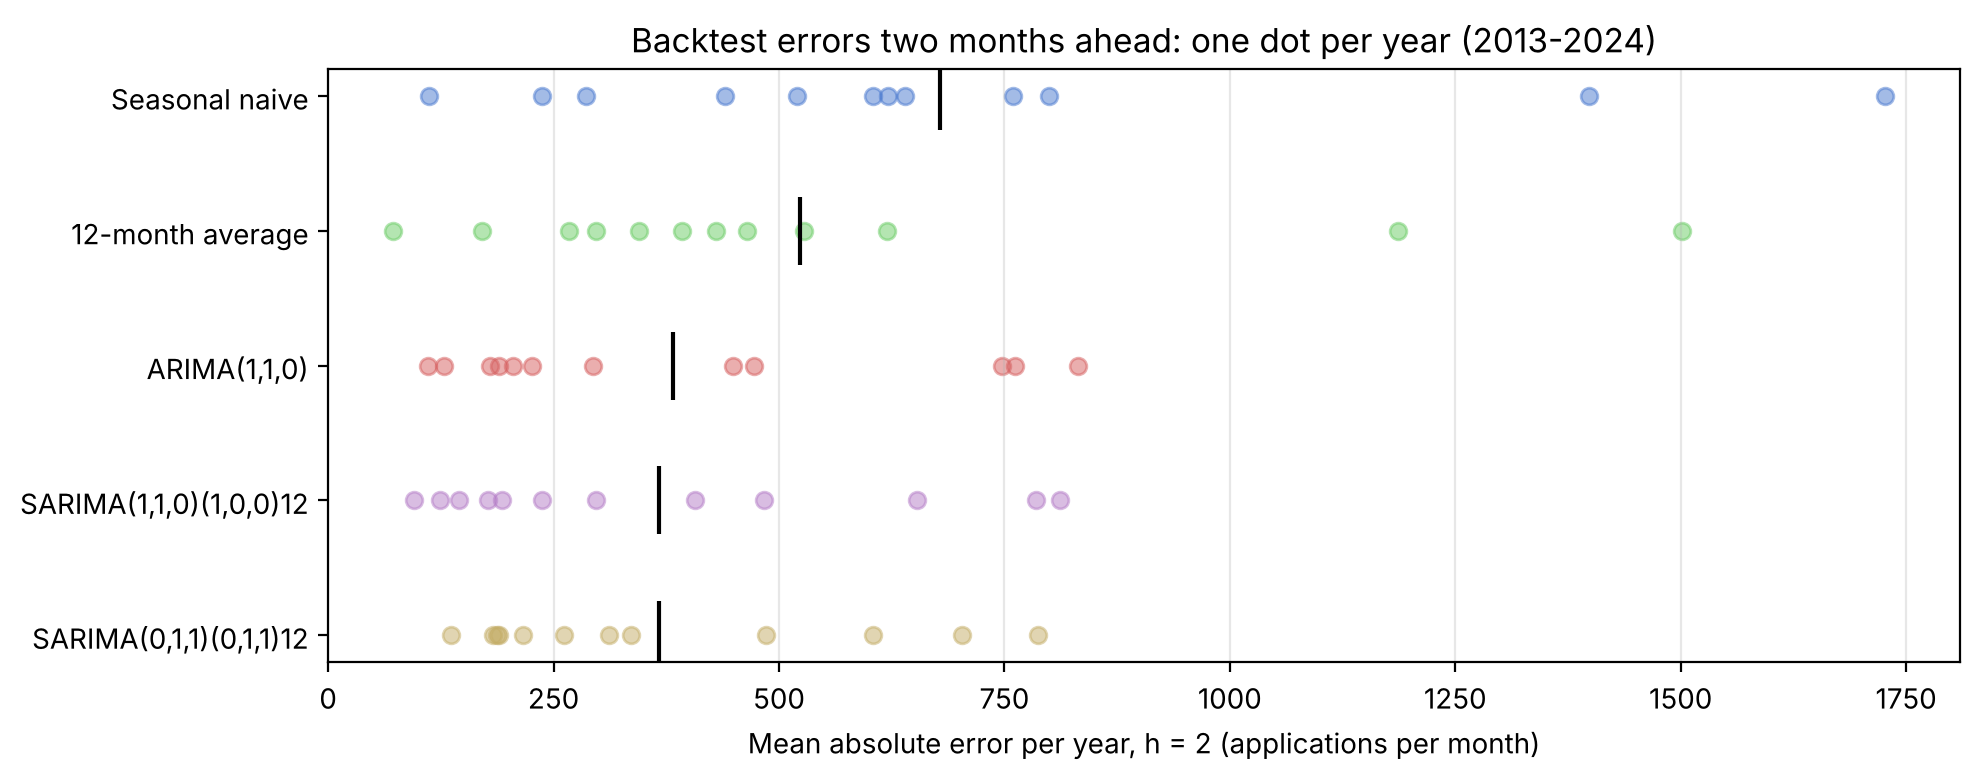

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
for i, name in enumerate(model_order):
    errors_by_year = by_year[name]
    ax.scatter(errors_by_year, [i] * len(errors_by_year), alpha=0.5)
    ax.scatter([errors_by_year.mean()], [i], marker="|", s=600, color="black")
ax.set_yticks(range(len(model_order)))
ax.set_yticklabels(model_order)
ax.invert_yaxis()
ax.set_xlim(left=0)
ax.set_xlabel("Mean absolute error per year, h = 2 (applications per month)")
ax.set_title("Backtest errors two months ahead: one dot per year (2013-2024)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("../output/figures/03_errors_by_year_h2.png")
plt.show()

**What we see.**
- SARIMA(0,1,1)(0,1,1)12 has a lower MAE than the 12-month average in 8 of the 12 years. It loses in 2014, 2018, 2019 and 2023 (table above).
- The spread across the years is large: the standard deviation of the yearly MAE is 417 for the 12-month average and 223 for the SARIMA model. The gap between their averages (156) is smaller than this spread, as in the comparison of Ridge and Lasso in notebook 209.
- In the picture, the two dots far to the right of the 12-month average (about 1,190 and 1,500) are the years 2016 and 2015. In calm years, the simple rule can win: in 2019, the 12-month average (72 persons) is better than every (S)ARIMA model, and in 2018 it is better than SARIMA(0,1,1)(0,1,1)12 (171 against 187).

**What this means for us.** The (S)ARIMA advantage is consistent (8 of 12 years), but not overwhelming: it comes mostly from the years with big changes. We will report it in this honest way. Between the three (S)ARIMA models, the differences are much smaller than the spread across years; following notebook 209 (Step 7), the simpler model is a serious candidate when the difference is within the noise.

## 6. Errors over the horizon

How fast do the errors grow when we forecast further ahead? We plot the MAE of each model for $h = 1, 2, 3$.

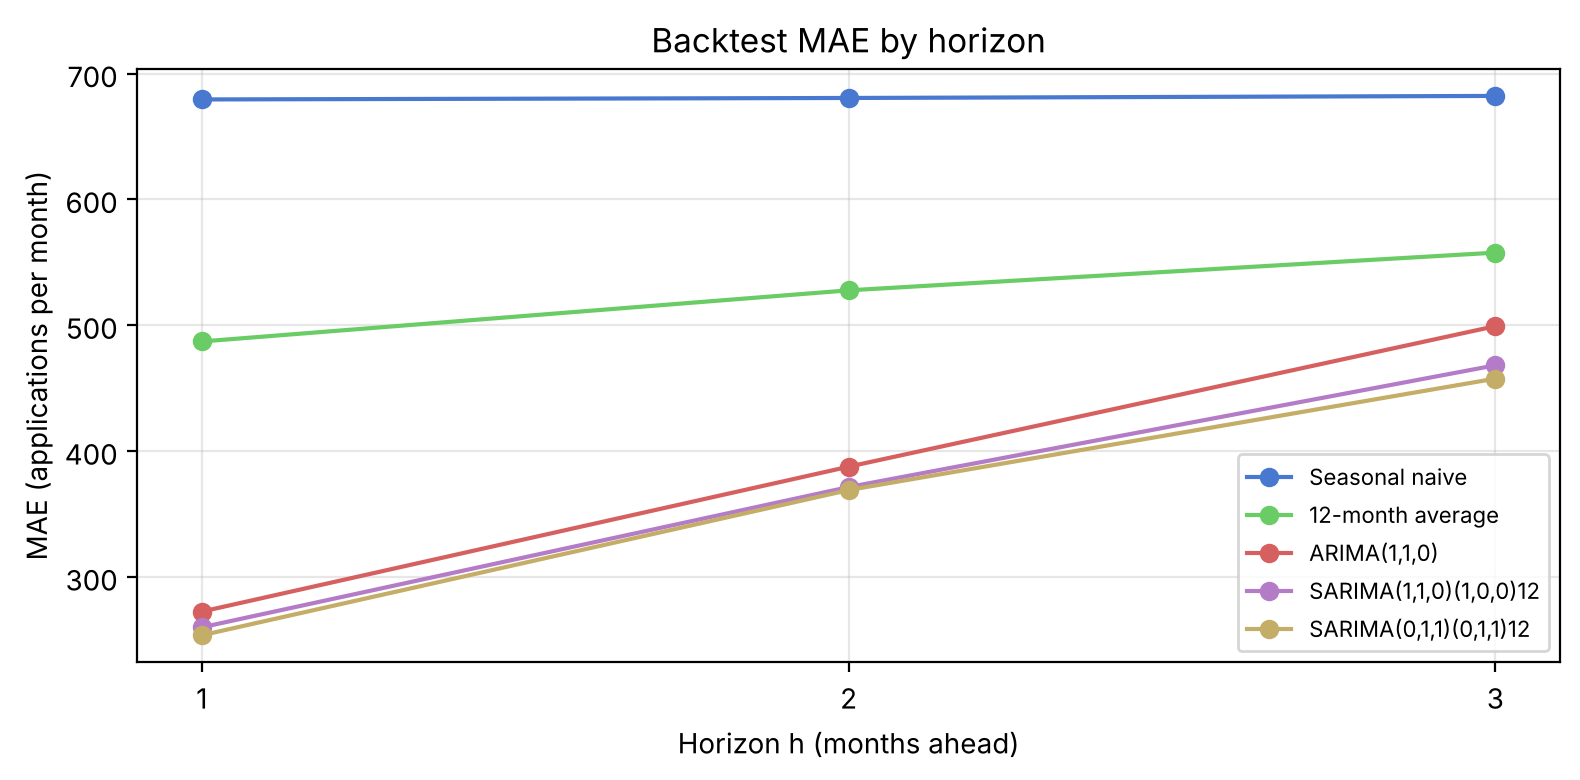

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
for name in model_order:
    one = errors[errors["model"] == name]
    ax.plot(one["h"], one["MAE (persons)"], marker="o", label=name)
ax.set_xticks([1, 2, 3])
ax.set_xlabel("Horizon h (months ahead)")
ax.set_ylabel("MAE (applications per month)")
ax.set_title("Backtest MAE by horizon")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../output/figures/03_mae_by_horizon.png")
plt.show()

**What we see.** For the three (S)ARIMA models, the MAE grows steadily from $h = 1$ to $h = 3$ (for example from 254 to 458 for SARIMA(0,1,1)(0,1,1)12), as expected: the further ahead, the less the recent months tell us (notebook 202). The 12-month average grows more slowly (487 to 558), and the seasonal naive stays flat at about 680. At every horizon, the (S)ARIMA models remain below both baselines, but at $h = 3$ the gap between ARIMA(1,1,0) (499) and the 12-month average (558) is small.

## Summary

- **Main comparison ($h = 2$):** best simple baseline = 12-month average (MAE 528 persons); best (S)ARIMA model = SARIMA(0,1,1)(0,1,1)12 (MAE 369 persons): **30% lower MAE**, 20% lower RMSE (log).
- **Robustness:** the (S)ARIMA models are better in all three periods, but the advantage is smaller without 2015-16 and 2020, and the (S)ARIMA models win in 8 of 12 years. The gap is smaller than the spread across years.
- **Between the (S)ARIMA models:** small differences; the best one changes with the period.
- **Next steps:** the best (S)ARIMA model is the benchmark for the next candidates (Ridge/Lasso with lags, then indicators). The final choice is made on the backtest; only then do we use the test period, once.